### Assignment 2 — Discrete and Continuous Probability Models ###

Participants:
- Dimitar Asenov Nizamov - 34468
- Marius Marcoci - 345963
- Plamen Plamenov Michev - 343810

In [1]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom
from scipy.stats import poisson
from scipy.stats import uniform
from scipy.stats import norm
from scipy.stats import expon
data1 = pd.read_csv('assignment02_concrete_strength.csv')
data2 = pd.read_csv('assignment02_service_repairs.csv')

## Part 1 — Cooling-unit failures: a finite random variable

Let $X$ be the number of cooling units that fail during a weekly maintenance window. The engineering model is

| $x$ | **0** | **1** | **2** | **3** | **4** |
| :---: | :---: | :---: | :---: | :---: | :---: |
| $P(X = x)$ | 0.58 | 0.26 | 0.10 | 0.04 | 0.02 |

#### a) Verify that the table is a valid PMF, state the support, and distinguish the random variable $X$ from an observed value $x$ ####

- A discrete function is a valid PMF if all probabilities are non-negative and sum to 1: 0.58 + 0.26 + 0.10 + 0.04 + 0.02 = 1.00
- supp(X) = {0,1,2,3,4}
- $X$ denotes the random variable itself, representing the unobserved outcome of the experiment before it happens
- $x$ denotes a specific realized or observed value resulting from the experiment

#### b) Construct a table containing $x, p_X(x)$, and $F_X(x)$. Use it to calculate $P(X = 2)$, $P(X \le 1), P(X \ge 2)$, and $P(1 < X \le 3)$. ####

In [4]:
x_values = [0, 1, 2, 3, 4]
p_x_values = [0.58, 0.26, 0.10, 0.04, 0.02]

df = pd.DataFrame({
    'x': x_values,
    'p_X(x)': p_x_values
})

df['F_X(x)'] = df['p_X(x)'].cumsum()
print(df.to_string(index=False))

first = df.loc[df['x'] == 2, 'p_X(x)'].values[0]
print(f"P(X = 2) = {first}")

second = df.loc[df['x'] == 1, 'F_X(x)'].values[0]
print(f"P(X <= 1) = {second}")

third = 1 - second
print(f"P(X >= 2) = {third}")

fourth = df.loc[df['x'] == 3, 'F_X(x)'].values[0]
p_1_lt_x_leq_3 = fourth - second
print(f"P(1 < X <= 3) = {p_1_lt_x_leq_3}")

 x  p_X(x)  F_X(x)
 0    0.58    0.58
 1    0.26    0.84
 2    0.10    0.94
 3    0.04    0.98
 4    0.02    1.00
P(X = 2) = 0.1
P(X <= 1) = 0.84
P(X >= 2) = 0.16000000000000003
P(1 < X <= 3) = 0.14


#### c) Plot the PMF as a bar chart and the CDF as a step plot. Explain the meaning of the height at each value in both plots. ####

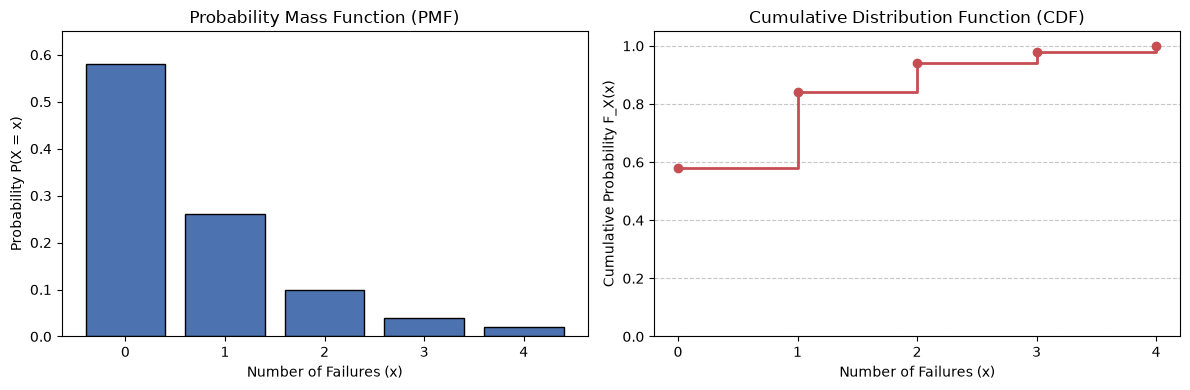

In [7]:
x_values = df['x']
p_x_values = df['p_X(x)']
F_x_values = df['F_X(x)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(x_values, p_x_values, color='#4C72B0', edgecolor='black')
ax1.set_title('Probability Mass Function (PMF)')
ax1.set_xlabel('Number of Failures (x)')
ax1.set_ylabel('Probability P(X = x)')
ax1.set_xticks(x_values)
ax1.set_ylim(0, 0.65)

ax2.step(x_values, F_x_values, where='post', color='#C44E52', marker='o', linewidth=2)
ax2.set_title('Cumulative Distribution Function (CDF)')
ax2.set_xlabel('Number of Failures (x)')
ax2.set_ylabel('Cumulative Probability F_X(x)')
ax2.set_xticks(x_values)
ax2.set_ylim(0, 1.05) 
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

- Bar Chart - the height of the bar at a specific value $x$ represents the exact probability that exactly $x$ cooling units fail during the week
- Step Plot - the height of the flat line starting at value $x$ represents the accumulated probability that *$x$ or fewer* cooling units fail

#### d) Calculate and interpret $E[X]$, $Var(X)$, and $SD(X)$ ####

In [ ]:
expected_value = (df['x'] * df['p_X(x)']).sum()
print(f"E[X] = {expected_value:.2f}")

e_x_squared = ((df['x']**2) * df['p_X(x)']).sum()
variance = e_x_squared - (expected_value**2)
print(f"Var(X) = {variance:.4f}")

std_deviation = np.sqrt(variance)
print(f"SD(X) = {std_deviation:.4f}")

E[X] = 0.66
Var(X) = 0.9044
SD(X) = 0.9510


## Part 2 — Repeated-event count models
### Late supplier deliveries: binomial

A project expects 30 deliveries. Each is modelled as late with probability 0.12 independently of the others. Let $B$ be the number of late deliveries.

#### a. Justify $B \sim \text{Bin}(30, 0.12)$. Identify the Bernoulli trial and discuss fixed $n$, constant $p$, independence, and one realistic violation.

- Bernoulli trial - a single trial checks the status of one delivery, where success means the delivery is late and failue means the delivery arrived on time
- $n$ - the project expects exactly 30 deliveries
- $p$ - the probability of a delivery being late is 0.12
- Independence - it is assumed that one delivery arriving late does not change the probability of any other delivey arriving late
- Violation - in reality deliveries might share the same supply chain and cause following deliveries to be late. For example, the same traffic jam can cause 2 different deliveries to be late, even though they are not related to each other.

#### b. Use SciPy to calculate $P(B = 3), P(B \le 4)$, and $P(B \ge 5)$. For $P(B = 3)$, also show the binomial formula and explain $\binom{n}{k}$. For the upper tail, explain the correct survival-function argument.

In [12]:
n = 30
p = 0.12

first = binom.pmf(3, n, p)
print(f"P(B = 3) = {first:.4f}")

second = binom.cdf(4, n, p)
print(f"P(B <= 4) = {second:.4f}")

third = binom.sf(4, n, p)
print(f"P(B >= 5) = {third:.4f}")

P(B = 3) = 0.2224
P(B <= 4) = 0.7118
P(B >= 5) = 0.2882


#### c. Calculate and interpret the mean and standard deviation.

In [13]:
mean, var = binom.stats(n, p, moments='mv')
std_dev = binom.std(n, p)

print(f"Mean = {mean:.2f}")
print(f"Standard Deviation = {std_dev:.2f}")

Mean = 3.60
Standard Deviation = 1.78


### Production stoppages: Poisson
Short stoppages are modelled as a Poisson process with mean 1.6 per 8-hour shift. Let $Y$ be the count during one shift.

#### a. State the model, parameter, support, mean, and variance. Calculate $P(Y = 0)$ and $P(Y \ge 3)$ for one shift.

- Model - poisson distribution
- Parameter - $\Lambda$ = 1.6
- Support - {0, 1, 2, ...}
- Mean - 1.6
- Variance - 1.6

In [15]:
lambda_val = 1.6

first = poisson.pmf(0, lambda_val)
print(f"P(Y = 0) = {first:.4f}")

second = poisson.sf(2, lambda_val)
print(f"P(Y >= 3) = {second:.4f}")

P(Y = 0) = 0.2019
P(Y >= 3) = 0.2166


#### b. Scale the expected count and calculate the probability of at least three stoppages in 24 hours. Discuss the stable-rate and independent-event assumptions.

- Stable-rate assumptions - frequency of events remains the same throughout the entire observation period. This is not always true because, for example, during the day, equipment can have more workload than during the night, causing failures and making the rate no longer stable
- Independent-events assumptions - one event happening does not influence in any way the probability of other events to happen. This can also not always be true because, for example, if a machine fails, higher workload can be put on other machines, increasing the chance of them to fail too

In [17]:
lambda_value = 1.6 * (24 / 8)
print(f"Scaled expected count for 24 hours = {lambda_value:.1f}")

calc = poisson.sf(2, lambda_value)
print(f"P(Y >= 3) in 24 hours = {calc:.4f}")

Scaled expected count for 24 hours = 4.8
P(Y >= 3) in 24 hours = 0.8575


## Part 3 — Uniform and normal models

### Sensor polling delay: uniform ###

A monitoring device polls a sensor once every 12 seconds. An event is assumed to occur at a random point in the cycle, so the delay $D$ until the next poll is modelled as $D \sim \text{Uniform}(0, 12)$.

#### a. Create the SciPy model using the correct location and scale. Plot its PDF and CDF and explain the support, constant density, and why $P(D = d) = 0$.

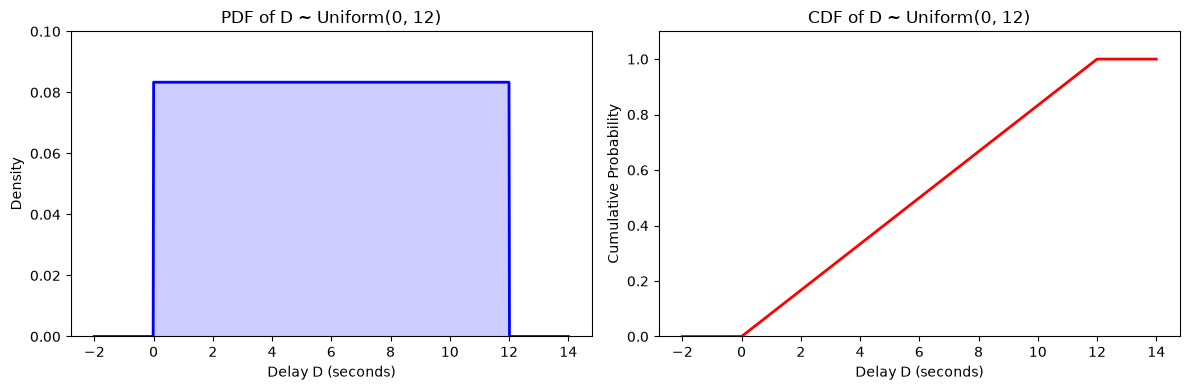

In [4]:
D = uniform(loc=0, scale=12)

x = np.linspace(-2, 14, 1000)

pdf = D.pdf(x)
cdf = D.cdf(x)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(x, pdf, lw=2, color='blue')
ax1.fill_between(x, pdf, alpha=0.2, color='blue')
ax1.set_title('PDF of D ~ Uniform(0, 12)')
ax1.set_xlabel('Delay D (seconds)')
ax1.set_ylabel('Density')
ax1.set_ylim(0, 0.1)

ax2.plot(x, cdf, lw=2, color='red')
ax2.set_title('CDF of D ~ Uniform(0, 12)')
ax2.set_xlabel('Delay D (seconds)')
ax2.set_ylabel('Cumulative Probability')
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

#### b. Calculate $P(D \leq 3)$, $P(4 < D < 9)$, $P(D > 10)$, the mean, standard deviation, and $95^{\text{th}}$ percentile.

In [21]:
D = uniform(loc=0, scale=12)

first = D.cdf(3)
second = D.cdf(9) - D.cdf(4)
third = D.sf(10) 

mean_val = D.mean()
std_val = D.std()
percentile_95 = D.ppf(0.95)

print(f"P(D <= 3) = {first:.4f}")
print(f"P(4 < D < 9) = {second:.4f}")
print(f"P(D > 10) = {third:.4f}")
print(f"Mean = {mean_val:.4f}")
print(f"Std Deviation = {std_val:.4f}")
print(f"95th Percentile = {percentile_95:.4f}")

P(D <= 3) = 0.2500
P(4 < D < 9) = 0.4167
P(D > 10) = 0.1667
Mean = 6.0000
Std Deviation = 3.4641
95th Percentile = 11.4000


### Concrete strength: normal working model ###

#### a. Report $n$, mean, median, and sample standard deviation. Fit $N(\hat{\mu}, \hat{\sigma}^2)$ and explain why SciPy receives $\hat{\sigma}$, not $\hat{\sigma}^2$, as `scale`.

In [26]:
data = data1['strength_mpa'].dropna()

n = len(data)
mean_val = data.mean()
median_val = data.median()
sample_std = data.std(ddof=1)

print(f"n = {n}")
print(f"Mean = {mean_val:.4f}")
print(f"Median = {median_val:.4f}")
print(f"Sample Std Dev = {sample_std:.4f}")

mu, sigma = norm.fit(data)

print(f"Fitted loc = {mu:.4f}")
print(f"Fitted scale = {sigma:.4f}")

# SciPy uses the standard deviation as the scale instead of the variance. 
# Therefore, the fitted scale parameter corresponds to the sample standard deviation, not the variance.

n = 160
Mean = 42.4942
Median = 42.3800
Sample Std Dev = 4.3429
Fitted loc = 42.4942
Fitted scale = 4.3293


#### b. Plot a density histogram with the fitted PDF and create a normal QQ-plot. Discuss symmetry, tails, unusual observations, and model adequacy.

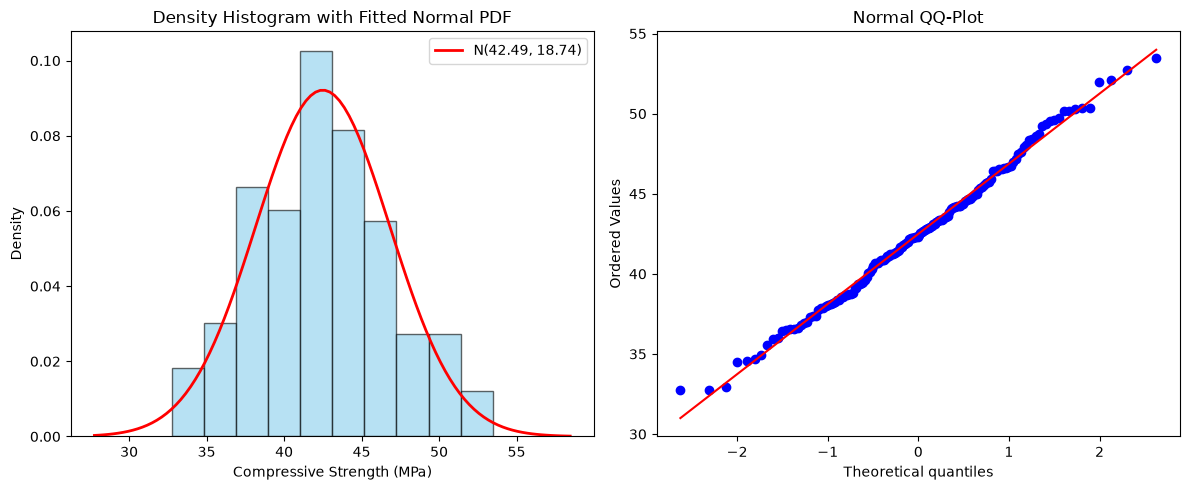

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(data, bins='auto', density=True, alpha=0.6, color='skyblue', edgecolor='black')

x = np.linspace(data.min() - 5, data.max() + 5, 100)
pdf = norm.pdf(x, loc=mu, scale=sigma)

ax1.plot(x, pdf, 'r-', lw=2, label=f'N({mu:.2f}, {sigma**2:.2f})')
ax1.set_title('Density Histogram with Fitted Normal PDF')
ax1.set_xlabel('Compressive Strength (MPa)')
ax1.set_ylabel('Density')
ax1.legend()

stats.probplot(data, dist="norm", plot=ax2)
ax2.set_title('Normal QQ-Plot')
ax2.get_lines()[0].set_markerfacecolor('blue')
ax2.get_lines()[0].set_markeredgecolor('blue')

plt.tight_layout()
plt.show()

- Symmetry - the density histogram shows that the data is symmetrical, forming a classic bell shape around the center
- Tails - the QQ plot shows that the blue dots follow very well the red line and there are no heavy tails or light tails
- Unusual observations - there aren't really any unusual observations, the histogram shows a normal distribution, and there aren't significant deviations from the red line in the QQ plot
- Model adequacy - considering that the plots are perfect, it means that the data fits well a normal distribution model

#### c. From the fitted model, calculate $P(X < 35)$, $P(38 < X < 46)$, the $95^{\text{th}}$ percentile, and the $z$-score of 35 MPa. Compare the first two model probabilities with empirical proportions.

In [20]:
first = norm.cdf(35, loc=mu, scale=sigma)

second = norm.cdf(46, loc=mu, scale=sigma) - norm.cdf(38, loc=mu, scale=sigma)

percentile_95 = norm.ppf(0.95, loc=mu, scale=sigma)

z_score = (35 - mu) / sigma

n = len(data)
first_empirical = (data < 35).sum() / n
second_empirical = ((data > 38) & (data < 46)).sum() / n

print(f"Model P(X < 35) = {first:.4f}")
print(f"Empirical P(X < 35) = {first_empirical:.4f}")
print(f"Model P(38 < X < 46) = {second:.4f}")
print(f"Empirical P(38 < X < 46) = {second_empirical:.4f}")
print(f"95th Percentile = {percentile_95:.4f}")
print(f"z-score of 35 MPa = {z_score:.4f}")

Model P(X < 35) = 0.0417
Empirical P(X < 35) = 0.0437
Model P(38 < X < 46) = 0.6414
Empirical P(38 < X < 46) = 0.6375
95th Percentile = 49.6153
z-score of 35 MPa = -1.7310


## Part 4 — Service restoration: an exponential working model

#### a. Report $n$, mean, median, sample standard deviation, minimum, and maximum. Plot a density histogram and describe the shape.

n = 180
Mean = 69.7986
Median = 49.3450
Sample Std Dev (s) = 67.4332
Minimum = 1.1100
Maximum = 410.6600


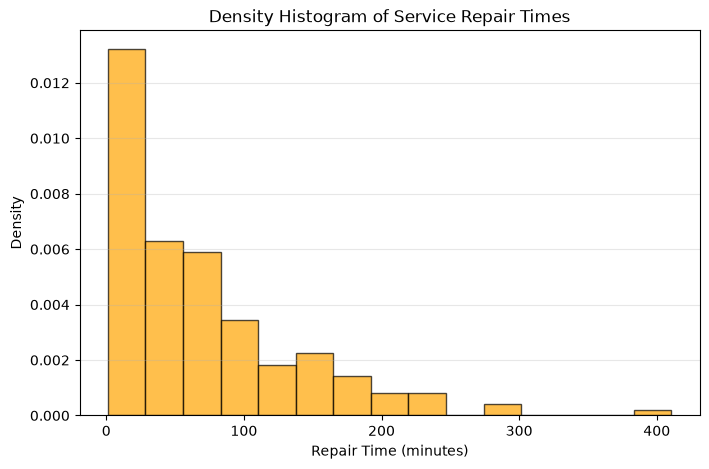

In [28]:
data = data2['repair_time_min'].dropna()

n = len(data)
mean_val = data.mean()
median_val = data.median()
sample_std = data.std(ddof=1)
min_val = data.min()
max_val = data.max()

print(f"n = {n}")
print(f"Mean = {mean_val:.4f}")
print(f"Median = {median_val:.4f}")
print(f"Sample Std Dev (s) = {sample_std:.4f}")
print(f"Minimum = {min_val:.4f}")
print(f"Maximum = {max_val:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(data, bins='auto', density=True, alpha=0.7, color='orange', edgecolor='black')
plt.title('Density Histogram of Service Repair Times')
plt.xlabel('Repair Time (minutes)')
plt.ylabel('Density')
plt.grid(axis='y', alpha=0.3)
plt.show()

The histogram shows a strongly right-skewed distribution. The highest density of observations is near zero, indicating that most repairs are completed relatively quickly. The frequencies then rapidly decay, forming a long, thin right tail that stretches out to show a few rare, highly time-consuming repairs. The fact that the mean (around 69.8) is noticeably larger than the median (around 49.3) also confirms this heavy right skew.

#### b. Fit an exponential model using $\hat{\lambda} = 1/\bar{x}$. State its fitted rate, mean, variance, and SciPy scale and add the fitted PDF to the histogram.

Fitted rate = 0.0143
Fitted mean = 69.7986
Fitted variance = 4871.8461
SciPy scale = 69.7986


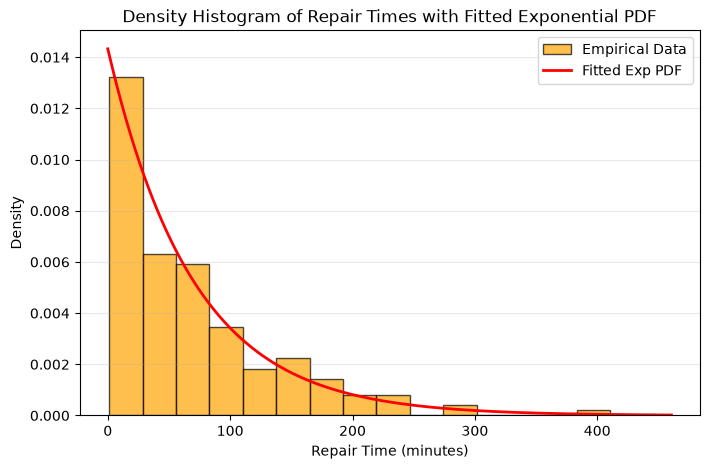

In [30]:
x_bar = data.mean()

lambda_hat = 1 / x_bar

fitted_mean = 1 / lambda_hat
fitted_variance = 1 / (lambda_hat**2)

scipy_scale = 1 / lambda_hat

print(f"Fitted rate = {lambda_hat:.4f}")
print(f"Fitted mean = {fitted_mean:.4f}")
print(f"Fitted variance = {fitted_variance:.4f}")
print(f"SciPy scale = {scipy_scale:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(data, bins='auto', density=True, alpha=0.7, color='orange', edgecolor='black', label='Empirical Data')

x = np.linspace(0, data.max() + 50, 1000)
pdf = expon.pdf(x, scale=scipy_scale)

plt.plot(x, pdf, 'r-', lw=2, label=f'Fitted Exp PDF')

plt.title('Density Histogram of Repair Times with Fitted Exponential PDF')
plt.xlabel('Repair Time (minutes)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

#### c. Compare empirical and fitted distributions using an empirical CDF with fitted CDF or an exponential QQ-plot. Discuss model strengths and limitations.

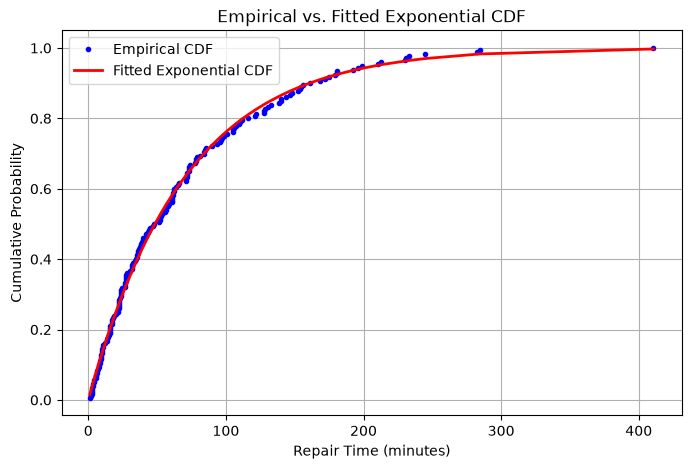

In [33]:
x_sorted = np.sort(data)
y_ecdf = np.arange(1, len(data) + 1) / len(data)

y_fitted = expon.cdf(x_sorted, scale=scipy_scale)

plt.figure(figsize=(8, 5))
plt.plot(x_sorted, y_ecdf, marker='.', linestyle='none', color='blue', label='Empirical CDF')
plt.plot(x_sorted, y_fitted, 'r-', lw=2, label='Fitted Exponential CDF')

plt.title('Empirical vs. Fitted Exponential CDF')
plt.xlabel('Repair Time (minutes)')
plt.ylabel('Cumulative Probability')
plt.legend()
plt.grid(True)
plt.show()

The empirical CDF aligns very closely with the fitted CDF, it captures the right skew and the high concentration of short repair times. By using an exponential model, we are forcing the assumption of memorylessness. It assumes that a repair doesn't progress in steady steps (like building a Lego set, where an hour of work means you are physically closer to being done). Instead, it assumes that if a repair has already taken 60 minutes, the probability of needing an additional 90 minutes is exactly the same as a brand-new, independent repair taking 90 minutes from the very start.

#### d. Calculate and interpret $P(T \leq 30)$, $P(T > 120)$, the median, and the $90^{\text{th}}$ percentile. Compare the two model probabilities with empirical proportions.

In [34]:
scipy_scale = data.mean()

first_model = expon.cdf(30, scale=scipy_scale)
second_model = expon.sf(120, scale=scipy_scale)
median_model = expon.ppf(0.5, scale=scipy_scale)
p90_model = expon.ppf(0.9, scale=scipy_scale)

n = len(data)
first_empirical = (data <= 30).sum() / n
second_empirical = (data > 120).sum() / n

print(f"Model P(T <= 30) = {first_model:.4f}")
print(f"Model P(T > 120) = {second_model:.4f}")
print(f"Model Median = {median_model:.4f} minutes")
print(f"Model 90th Percentile = {p90_model:.4f} minutes")

print(f"Empirical P(T <= 30)  = {first_empirical:.4f}")
print(f"Empirical P(T > 120)  = {second_empirical:.4f}")

Model P(T <= 30) = 0.3494
Model P(T > 120) = 0.1792
Model Median = 48.3807 minutes
Model 90th Percentile = 160.7172 minutes
Empirical P(T <= 30)  = 0.3611
Empirical P(T > 120)  = 0.2000


#### e. Calculate $P(T > 150 \mid T > 60)$ as both a ratio of survival probabilities and the probability of waiting an additional 90 minutes. Explain the memoryless and constant-rate assumptions.

In [35]:
first = expon.sf(150, scale=scipy_scale)
second = expon.sf(60, scale=scipy_scale)
conditional_prob = first / second

third = expon.sf(90, scale=scipy_scale)

print(f"Ratio P(T > 150) / P(T > 60) = {conditional_prob:.4f}")
print(f"P(T > 90) = {third:.4f}")

Ratio P(T > 150) / P(T > 60) = 0.2754
P(T > 90) = 0.2754


- Memoryless assumption - as the code output proves, the exponential model does not remember the 60 minutes that have already passed. It assumes that if a repair has dragged on for an hour, the probability of it taking an additional 90 minutes is exactly the same as a brand-new repair taking 90 minutes from scratch.
- Constant rate assumption - The model assumes that the likelihood of the repair finishing in the very next minute is driven by a constant rate. It implies the technician is not making cumulative progress toward a finish line, getting faster as they figure it out, or getting slower due to fatigue. The chance of finishing now remains permanently locked at that constant rate, regardless of whether 5 minutes or 5 hours have elapsed.

## Part5 - AI use and conclusion

#### AI Use

We have used Google Gemini in this hand-in to help us generate the code for the plots and for the markdown of the task descriptions. With the plots, after not receiving any compilation errors and visually inspecting the plots, we concluded that the code is correct and there is no need for rejecting or changing it. 


#### Conclusion

The assignment compares discrete and continuous probability models, showing that four conditions are needed to calculate useful probabilities. First, we must define exactly what the support is. Second, the math must match real-world events, for example, a single traffic jam ruins the independent delivery assumption of a Binomial model, and one broken machine overworking others breaks a Poisson model's steady rate. Third, every mathematical model requires exact starting inputs to function correctly, whether that means providing a success rate for a Binomial model, an average event rate for a Poisson model, or a standard deviation for a continuous curve. Lastly, plots like histograms and QQ-plots hlep verify that the data actually fits the chosen model, which proves the calculations closely match empirical results.